In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes

# Load dataset
data = load_diabetes()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Dataset shape:", X.shape)
print("\nFirst 5 rows:")
print(X.head())

print("\nTarget values:")
print(y.head())

print("\nDataset description:")
print(data.DESCR[:1000])

Dataset shape: (442, 10)

First 5 rows:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  

Target values:
0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
Name: target, dtype: float64

Dataset description:
.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for

Missing values: 0

Feature summary:
                age           sex           bmi            bp            s1  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean  -2.511817e-19  1.230790e-17 -2.245564e-16 -4.797570e-17 -1.381499e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02   
min   -1.072256e-01 -4.464164e-02 -9.027530e-02 -1.123988e-01 -1.267807e-01   
25%   -3.729927e-02 -4.464164e-02 -3.422907e-02 -3.665608e-02 -3.424784e-02   
50%    5.383060e-03 -4.464164e-02 -7.283766e-03 -5.670422e-03 -4.320866e-03   
75%    3.807591e-02  5.068012e-02  3.124802e-02  3.564379e-02  2.835801e-02   
max    1.107267e-01  5.068012e-02  1.705552e-01  1.320436e-01  1.539137e-01   

                 s2            s3            s4            s5            s6  
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  
mean   3.918434e-17 -5.777179e-18 -9.042540e-18  9.293722e-17  1.130318e-17  
std    4.761905e-0

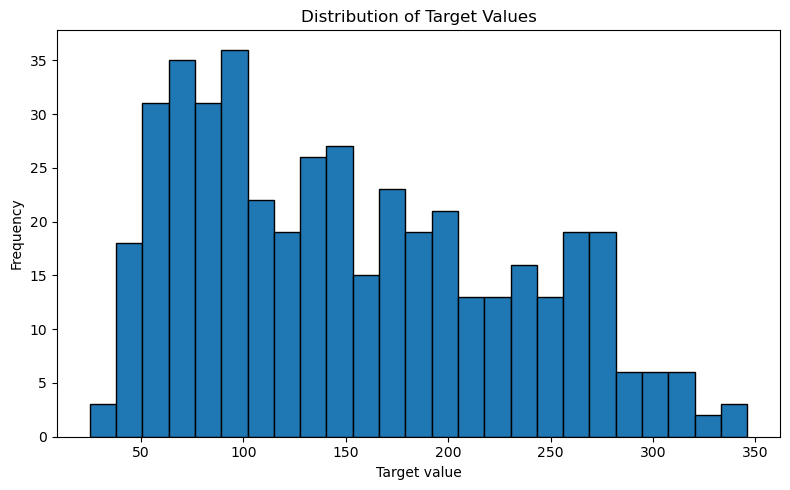

In [2]:
# Check missing values
print("Missing values:", X.isnull().sum().sum())

# Statistical summary
print("\nFeature summary:")
print(X.describe())

# Visualize target distribution
plt.figure(figsize=(8, 5))
plt.hist(y, bins=25, edgecolor="black")
plt.xlabel("Target value")
plt.ylabel("Frequency")
plt.title("Distribution of Target Values")
plt.tight_layout()
plt.show()

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 353
Testing samples: 89


In [4]:
from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Regression Tree trained successfully!")

Regression Tree trained successfully!


In [5]:
y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.head(10).to_list())

print("\nPredicted values:")
print(np.round(y_pred[:10], 2))

Actual values:
[219.0, 70.0, 202.0, 230.0, 111.0, 84.0, 242.0, 272.0, 94.0, 96.0]

Predicted values:
[190.68 182.77 190.68 218.92 121.86  90.33 225.75 218.92 109.3  182.77]


In [6]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.2f}")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

MAE:  43.44
MSE:  2997.90
RMSE: 54.75
R² Score: 0.4342


In [7]:
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

print("Training R²:", round(r2_score(y_train, train_pred), 4))
print("Testing R²: ", round(r2_score(y_test, test_pred), 4))

Training R²: 0.575
Testing R²:  0.4342


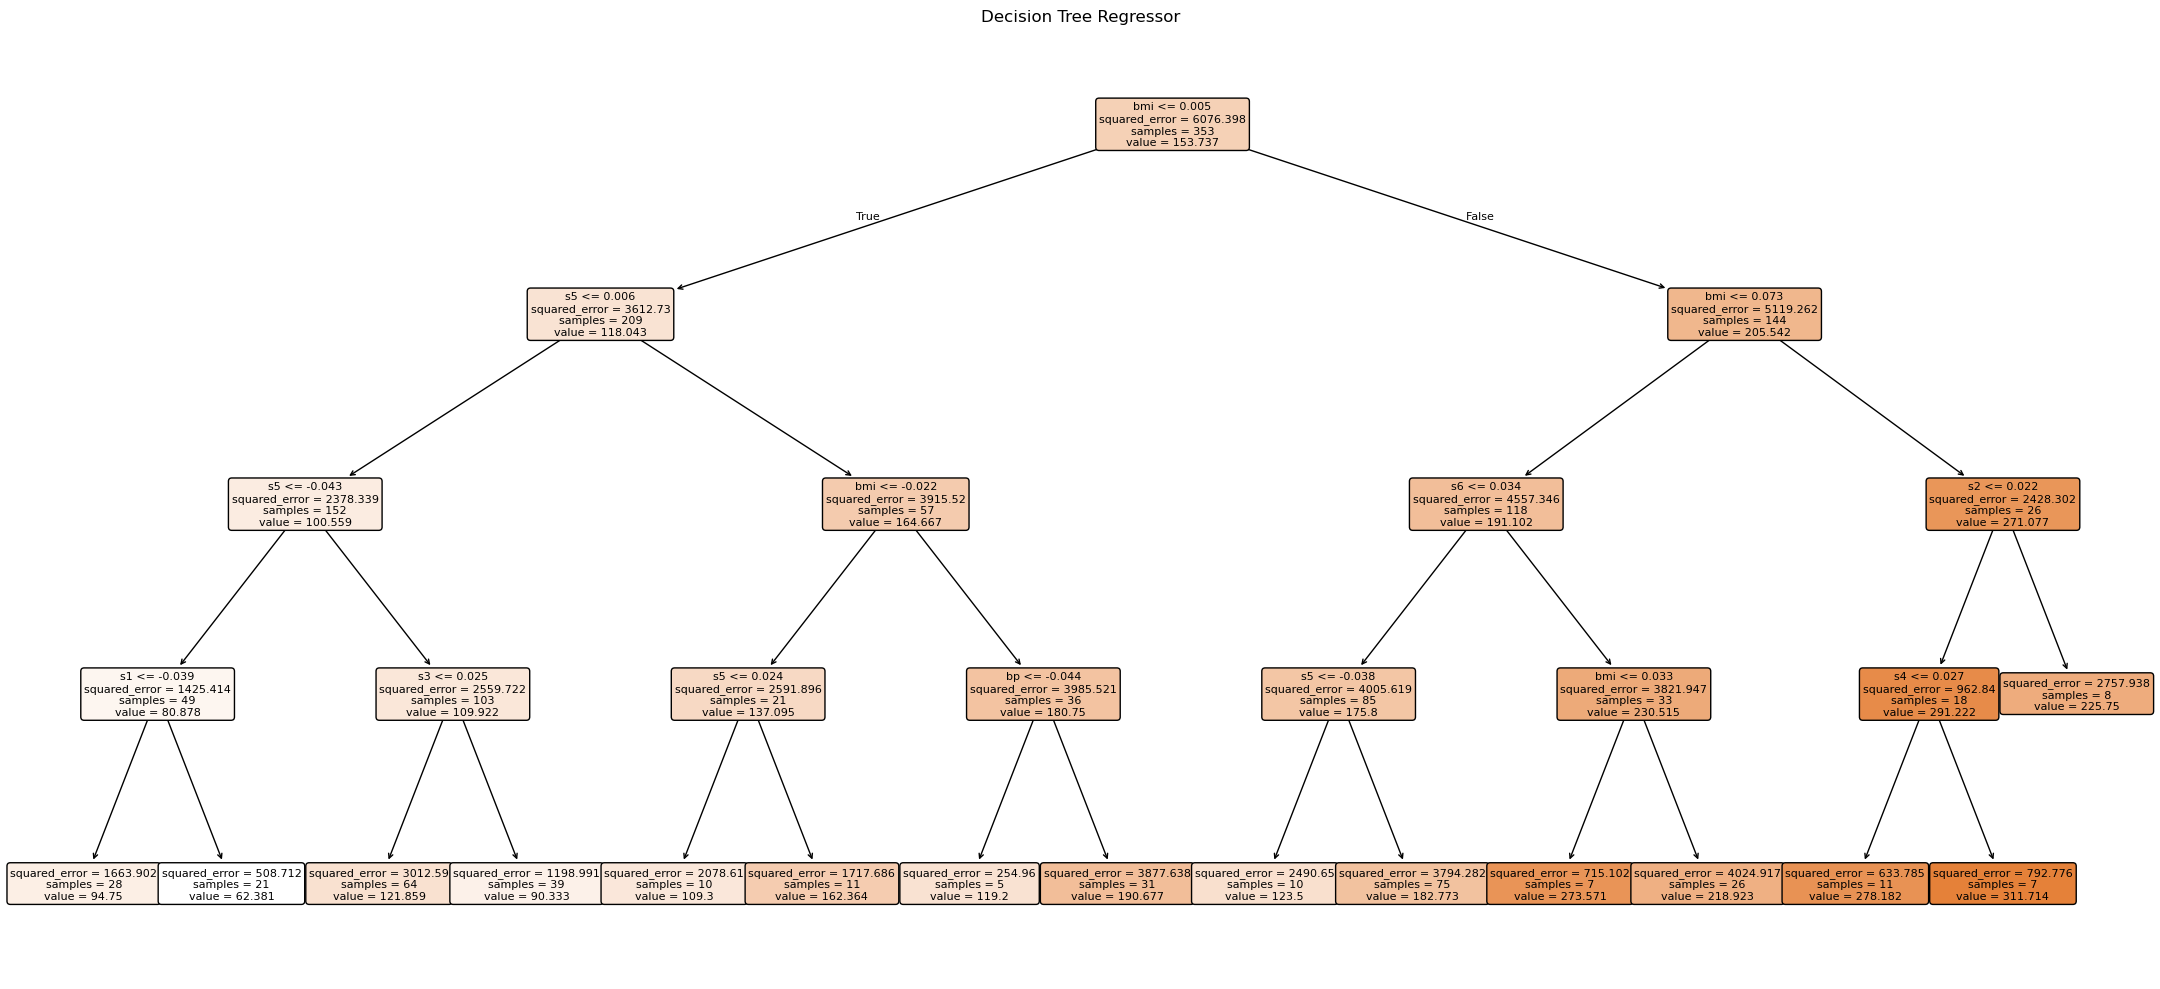

In [8]:
from sklearn.tree import plot_tree

plt.figure(figsize=(22, 10))

plot_tree(
    model,
    feature_names=data.feature_names,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Regressor")
plt.tight_layout()
plt.show()

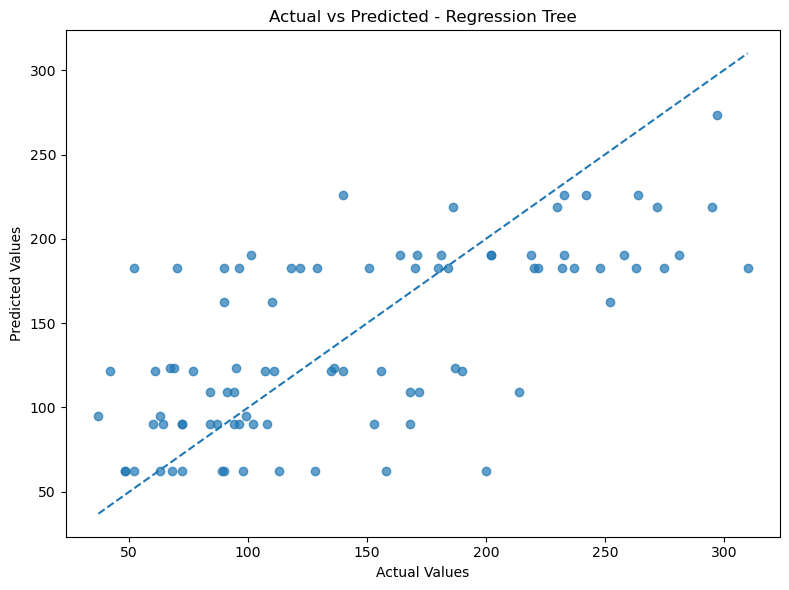

In [9]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Ideal prediction line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted - Regression Tree")
plt.tight_layout()
plt.show()

  Feature  Importance
2     bmi    0.673627
8      s5    0.197955
9      s6    0.057705
6      s3    0.019530
5      s2    0.019251
3      bp    0.017837
4      s1    0.010195
7      s4    0.003900
0     age    0.000000
1     sex    0.000000


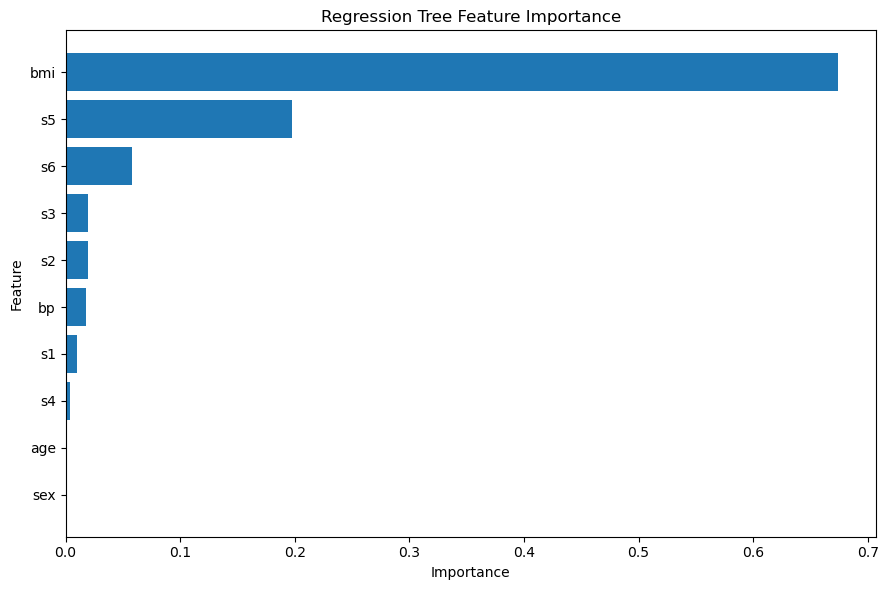

In [10]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

plt.figure(figsize=(9, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Regression Tree Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "max_depth": [2, 3, 4, 5, 6, 8, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "criterion": ["squared_error", "absolute_error"]
}

grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(np.sqrt(-grid_search.best_score_))

# Evaluate the selected model on the held-out test set
best_model = grid_search.best_estimator_
best_pred = best_model.predict(X_test)

print("\nTest MAE:", round(mean_absolute_error(y_test, best_pred), 2))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, best_pred)), 2))
print("Test R²:", round(r2_score(y_test, best_pred), 4))

Best Parameters:
{'criterion': 'squared_error', 'max_depth': 2, 'min_samples_leaf': 1, 'min_samples_split': 2}

Best Cross-Validation RMSE:
61.43653552107067

Test MAE: 49.37
Test RMSE: 61.12
Test R²: 0.2949


Exception ignored in: <function ResourceTracker.__del__ at 0x102945bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1035a1bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x106f25bc0>
Traceback (most recent call last